In [12]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import AutoTokenizer , AutoModel

MODEL_NAME="distilbert/distilgpt2"
DEVICE= "cuda" if torch.cuda.is_available() else "cpu"

print("device",DEVICE)

device cpu


In [3]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)
model=AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()
print("model loaded sccesfully")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

model loaded sccesfully


In [4]:
config = model.config

print("Model name:", MODEL_NAME)

print("Hidden dimension:", config.hidden_size)

print("Transformer layers:", config.n_layer)

print("Attention heads:", config.n_head)

print("Vocabulary size:", config.vocab_size)

print("Maximum sequence length:", config.n_positions)

Model name: distilbert/distilgpt2
Hidden dimension: 768
Transformer layers: 6
Attention heads: 12
Vocabulary size: 50257
Maximum sequence length: 1024


In [5]:
print(model)

GPT2Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(1024, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (h): ModuleList(
    (0-5): 6 x GPT2Block(
      (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): GPT2Attention(
        (c_attn): Conv1D(nf=2304, nx=768)
        (c_proj): Conv1D(nf=768, nx=768)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): GPT2MLP(
        (c_fc): Conv1D(nf=3072, nx=768)
        (c_proj): Conv1D(nf=768, nx=3072)
        (act): NewGELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
)


In [6]:
transformer_blocks = model.h

print("Total Transformer blocks:", len(transformer_blocks))

for i, block in enumerate(transformer_blocks):

    print(f"\nTransformer Block {i}")

    print(block)

Total Transformer blocks: 6

Transformer Block 0
GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

Transformer Block 1
GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c

In [7]:
block = model.h[0]

print("Attention layer:")
print(block.attn)

print("\nFeed-forward layer:")
print(block.mlp)

print("\nLayer normalization:")
print(block.ln_1)
print(block.ln_2)

Attention layer:
GPT2Attention(
  (c_attn): Conv1D(nf=2304, nx=768)
  (c_proj): Conv1D(nf=768, nx=768)
  (attn_dropout): Dropout(p=0.1, inplace=False)
  (resid_dropout): Dropout(p=0.1, inplace=False)
)

Feed-forward layer:
GPT2MLP(
  (c_fc): Conv1D(nf=3072, nx=768)
  (c_proj): Conv1D(nf=768, nx=3072)
  (act): NewGELUActivation()
  (dropout): Dropout(p=0.1, inplace=False)
)

Layer normalization:
LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)


In [8]:
text = "Artificial intelligence is changing the world."

inputs = tokenizer(text, return_tensors="pt")

inputs = {
    key: value.to(DEVICE)
    for key, value in inputs.items()
}

print("Input IDs:", inputs["input_ids"])

print("Input shape:", inputs["input_ids"].shape)

Input IDs: tensor([[8001, 9542, 4430,  318, 5609,  262,  995,   13]])
Input shape: torch.Size([1, 8])


In [9]:
with torch.no_grad():

    outputs = model(
        **inputs,
        output_hidden_states=True
    )

last_hidden_state = outputs.last_hidden_state

print("Final output shape:", last_hidden_state.shape)

print("Number of hidden-state tensors:", len(outputs.hidden_states))

Final output shape: torch.Size([1, 8, 768])
Number of hidden-state tensors: 7


In [10]:
for i, hidden_state in enumerate(outputs.hidden_states):

    print(
        f"Stage {i}:",
        tuple(hidden_state.shape)
    )

Stage 0: (1, 8, 768)
Stage 1: (1, 8, 768)
Stage 2: (1, 8, 768)
Stage 3: (1, 8, 768)
Stage 4: (1, 8, 768)
Stage 5: (1, 8, 768)
Stage 6: (1, 8, 768)


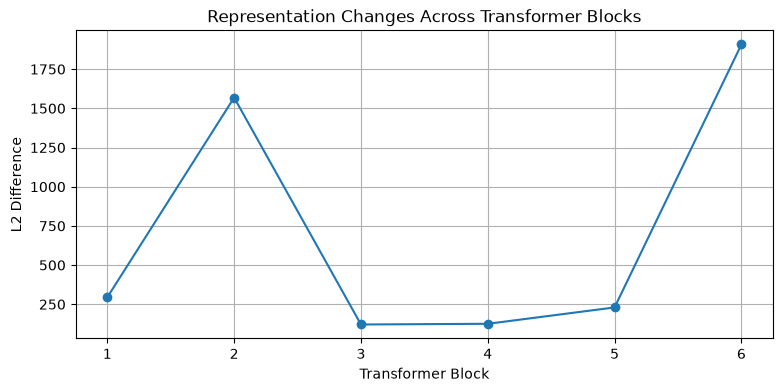

In [13]:
layer_changes = []

for i in range(1, len(outputs.hidden_states)):

    previous = outputs.hidden_states[i - 1]

    current = outputs.hidden_states[i]

    difference = torch.norm(current - previous).item()

    layer_changes.append(difference)

plt.figure(figsize=(9, 4))

plt.plot(
    range(1, len(outputs.hidden_states)),
    layer_changes,
    marker="o"
)

plt.title("Representation Changes Across Transformer Blocks")

plt.xlabel("Transformer Block")

plt.ylabel("L2 Difference")

plt.xticks(range(1, len(outputs.hidden_states)))

plt.grid(True)

plt.show()

In [14]:
from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np
import matplotlib.pyplot as plt

MODEL_NAME = "distilbert/distilgpt2"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModel.from_pretrained(
    MODEL_NAME,
    attn_implementation="eager"
).to(DEVICE)

model.eval()

print("Model loaded:", MODEL_NAME)
print("Attention implementation:", model.config._attn_implementation)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model loaded: distilbert/distilgpt2
Attention implementation: eager


In [15]:
text = "The cat is drinking milk."

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(DEVICE)

input_ids = inputs["input_ids"]

tokens = tokenizer.convert_ids_to_tokens(
    input_ids[0]
)

print("Tokens:", tokens)
print("Input shape:", input_ids.shape)

Tokens: ['The', 'Ġcat', 'Ġis', 'Ġdrinking', 'Ġmilk', '.']
Input shape: torch.Size([1, 6])


In [16]:
with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True
    )

attentions = outputs.attentions

print("Number of attention layers:", len(attentions))
print("Attention tensor shape:", attentions[0].shape)

Number of attention layers: 6
Attention tensor shape: torch.Size([1, 12, 6, 6])


In [17]:
# First layer, first attention head
attention_matrix = attentions[0][0, 0].cpu().numpy()

print("Attention matrix shape:", attention_matrix.shape)
print(attention_matrix)

Attention matrix shape: (6, 6)
[[1.         0.         0.         0.         0.         0.        ]
 [0.6121352  0.38786483 0.         0.         0.         0.        ]
 [0.6439045  0.28090122 0.07519432 0.         0.         0.        ]
 [0.27540037 0.32703248 0.10499695 0.2925702  0.         0.        ]
 [0.32885113 0.35959077 0.03472872 0.13454603 0.14228337 0.        ]
 [0.5251362  0.21165296 0.0516679  0.10423648 0.08612016 0.02118627]]


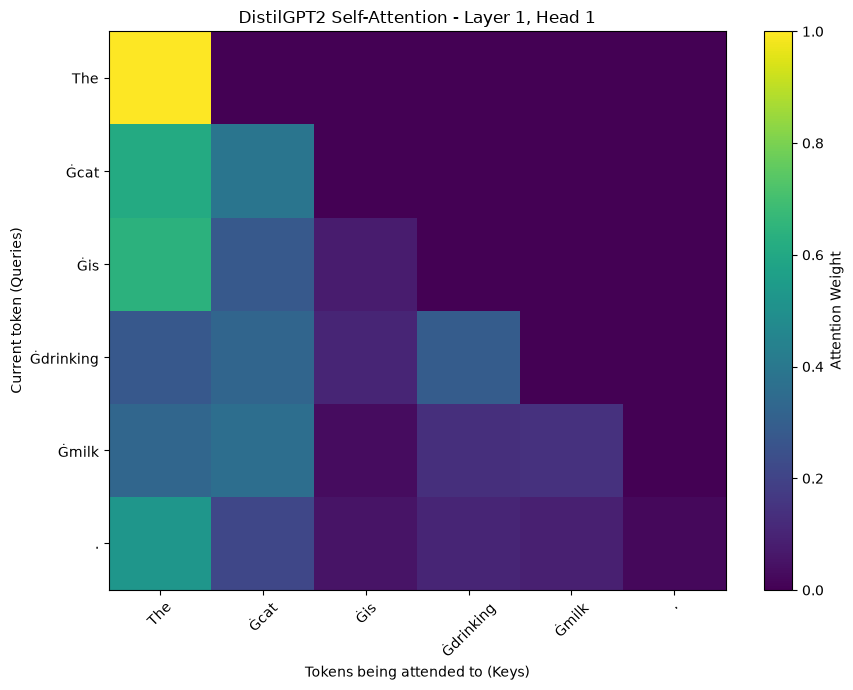

In [18]:
plt.figure(figsize=(9, 7))

plt.imshow(
    attention_matrix,
    cmap="viridis",
    aspect="auto"
)

plt.xticks(range(len(tokens)), tokens, rotation=45)
plt.yticks(range(len(tokens)), tokens)

plt.xlabel("Tokens being attended to (Keys)")
plt.ylabel("Current token (Queries)")
plt.title("DistilGPT2 Self-Attention - Layer 1, Head 1")

plt.colorbar(label="Attention Weight")
plt.tight_layout()
plt.show()

In [19]:
print("Attention matrix:")
print(np.round(attention_matrix, 3))

print("\nFuture-token attention weights:")

for i in range(len(tokens)):
    future_weights = attention_matrix[i, i + 1:]
    print(f"{tokens[i]}:", np.round(future_weights, 5))

Attention matrix:
[[1.    0.    0.    0.    0.    0.   ]
 [0.612 0.388 0.    0.    0.    0.   ]
 [0.644 0.281 0.075 0.    0.    0.   ]
 [0.275 0.327 0.105 0.293 0.    0.   ]
 [0.329 0.36  0.035 0.135 0.142 0.   ]
 [0.525 0.212 0.052 0.104 0.086 0.021]]

Future-token attention weights:
The: [0. 0. 0. 0. 0.]
Ġcat: [0. 0. 0. 0.]
Ġis: [0. 0. 0.]
Ġdrinking: [0. 0.]
Ġmilk: [0.]
.: []


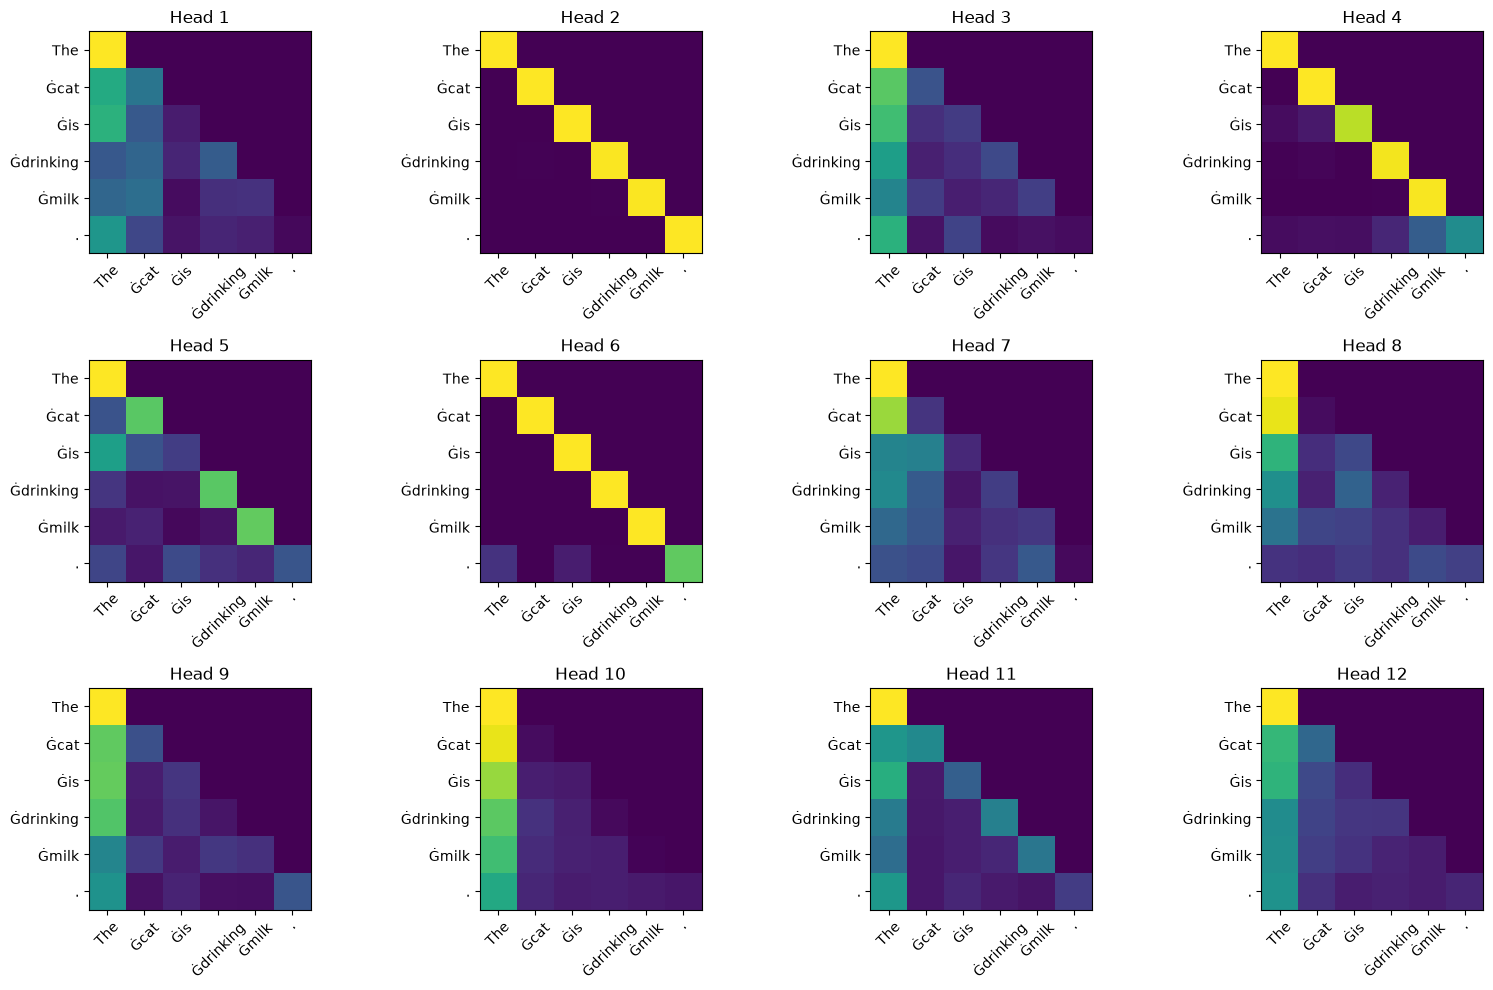

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for head in range(12):
    ax = axes[head // 4, head % 4]

    matrix = attentions[0][0, head].cpu().numpy()

    ax.imshow(matrix, cmap="viridis")
    ax.set_title(f"Head {head + 1}")
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=45)
    ax.set_yticks(range(len(tokens)))
    ax.set_yticklabels(tokens)

plt.tight_layout()
plt.show()

In [21]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilbert/distilgpt2"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.15.0+cpu


In [22]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(
    MODEL_NAME,
    attn_implementation="eager"
).to(DEVICE)
model.eval()

print("Model loaded:", MODEL_NAME)
print("Attention implementation:", model.config._attn_implementation)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model loaded: distilbert/distilgpt2
Attention implementation: eager


In [23]:
config = model.config
config_summary = {
    "hidden_size": config.hidden_size,
    "num_layers": config.n_layer,
    "num_heads": config.n_head,
    "head_dim": config.hidden_size // config.n_head,
    "intermediate_size": config.n_inner or 4 * config.hidden_size,
    "vocabulary_size": config.vocab_size,
    "maximum_positions": config.n_positions,
}
pd.Series(config_summary, name="Value")

hidden_size            768
num_layers               6
num_heads               12
head_dim                64
intermediate_size     3072
vocabulary_size      50257
maximum_positions     1024
Name: Value, dtype: int64

In [24]:
print(model)

GPT2Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(1024, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (h): ModuleList(
    (0-5): 6 x GPT2Block(
      (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): GPT2Attention(
        (c_attn): Conv1D(nf=2304, nx=768)
        (c_proj): Conv1D(nf=768, nx=768)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): GPT2MLP(
        (c_fc): Conv1D(nf=3072, nx=768)
        (c_proj): Conv1D(nf=768, nx=3072)
        (act): NewGELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
)


In [25]:
transformer_blocks = model.h
print("Total Transformer blocks:", len(transformer_blocks))
for index, block in enumerate(transformer_blocks):
    print(f"Block {index}:")
    print(" Attention:", type(block.attn).__name__)
    print(" MLP:", type(block.mlp).__name__)
    print(" LayerNorm 1:", type(block.ln_1).__name__)
    print(" LayerNorm 2:", type(block.ln_2).__name__)

Total Transformer blocks: 6
Block 0:
 Attention: GPT2Attention
 MLP: GPT2MLP
 LayerNorm 1: LayerNorm
 LayerNorm 2: LayerNorm
Block 1:
 Attention: GPT2Attention
 MLP: GPT2MLP
 LayerNorm 1: LayerNorm
 LayerNorm 2: LayerNorm
Block 2:
 Attention: GPT2Attention
 MLP: GPT2MLP
 LayerNorm 1: LayerNorm
 LayerNorm 2: LayerNorm
Block 3:
 Attention: GPT2Attention
 MLP: GPT2MLP
 LayerNorm 1: LayerNorm
 LayerNorm 2: LayerNorm
Block 4:
 Attention: GPT2Attention
 MLP: GPT2MLP
 LayerNorm 1: LayerNorm
 LayerNorm 2: LayerNorm
Block 5:
 Attention: GPT2Attention
 MLP: GPT2MLP
 LayerNorm 1: LayerNorm
 LayerNorm 2: LayerNorm


In [26]:
text = "The student is learning how transformers understand language."
inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

with torch.no_grad():
    outputs = model(
        **inputs,
        output_hidden_states=True,
        output_attentions=True,
        use_cache=False
    )

hidden_states = outputs.hidden_states
attentions = outputs.attentions

print("Tokens:", tokens)
print("Input shape:", tuple(inputs["input_ids"].shape))
print("Hidden-state tensors:", len(hidden_states))
print("Attention layers:", len(attentions))
for i, state in enumerate(hidden_states):
    print(f"Hidden state {i}: {tuple(state.shape)}")

Tokens: ['The', 'Ġstudent', 'Ġis', 'Ġlearning', 'Ġhow', 'Ġtransform', 'ers', 'Ġunderstand', 'Ġlanguage', '.']
Input shape: (1, 10)
Hidden-state tensors: 7
Attention layers: 6
Hidden state 0: (1, 10, 768)
Hidden state 1: (1, 10, 768)
Hidden state 2: (1, 10, 768)
Hidden state 3: (1, 10, 768)
Hidden state 4: (1, 10, 768)
Hidden state 5: (1, 10, 768)
Hidden state 6: (1, 10, 768)


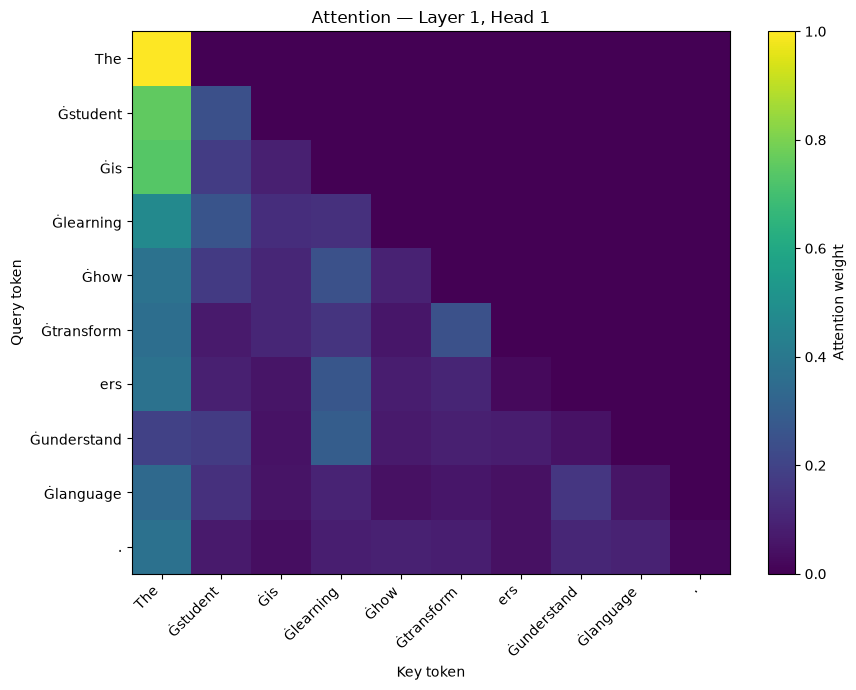

In [27]:
layer_index, head_index = 0, 0
attention_matrix = attentions[layer_index][0, head_index].detach().cpu().numpy()

plt.figure(figsize=(9, 7))
plt.imshow(attention_matrix, cmap="viridis", aspect="auto")
plt.xticks(range(len(tokens)), tokens, rotation=45, ha="right")
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.title(f"Attention — Layer {layer_index + 1}, Head {head_index + 1}")
plt.colorbar(label="Attention weight")
plt.tight_layout()
plt.show()

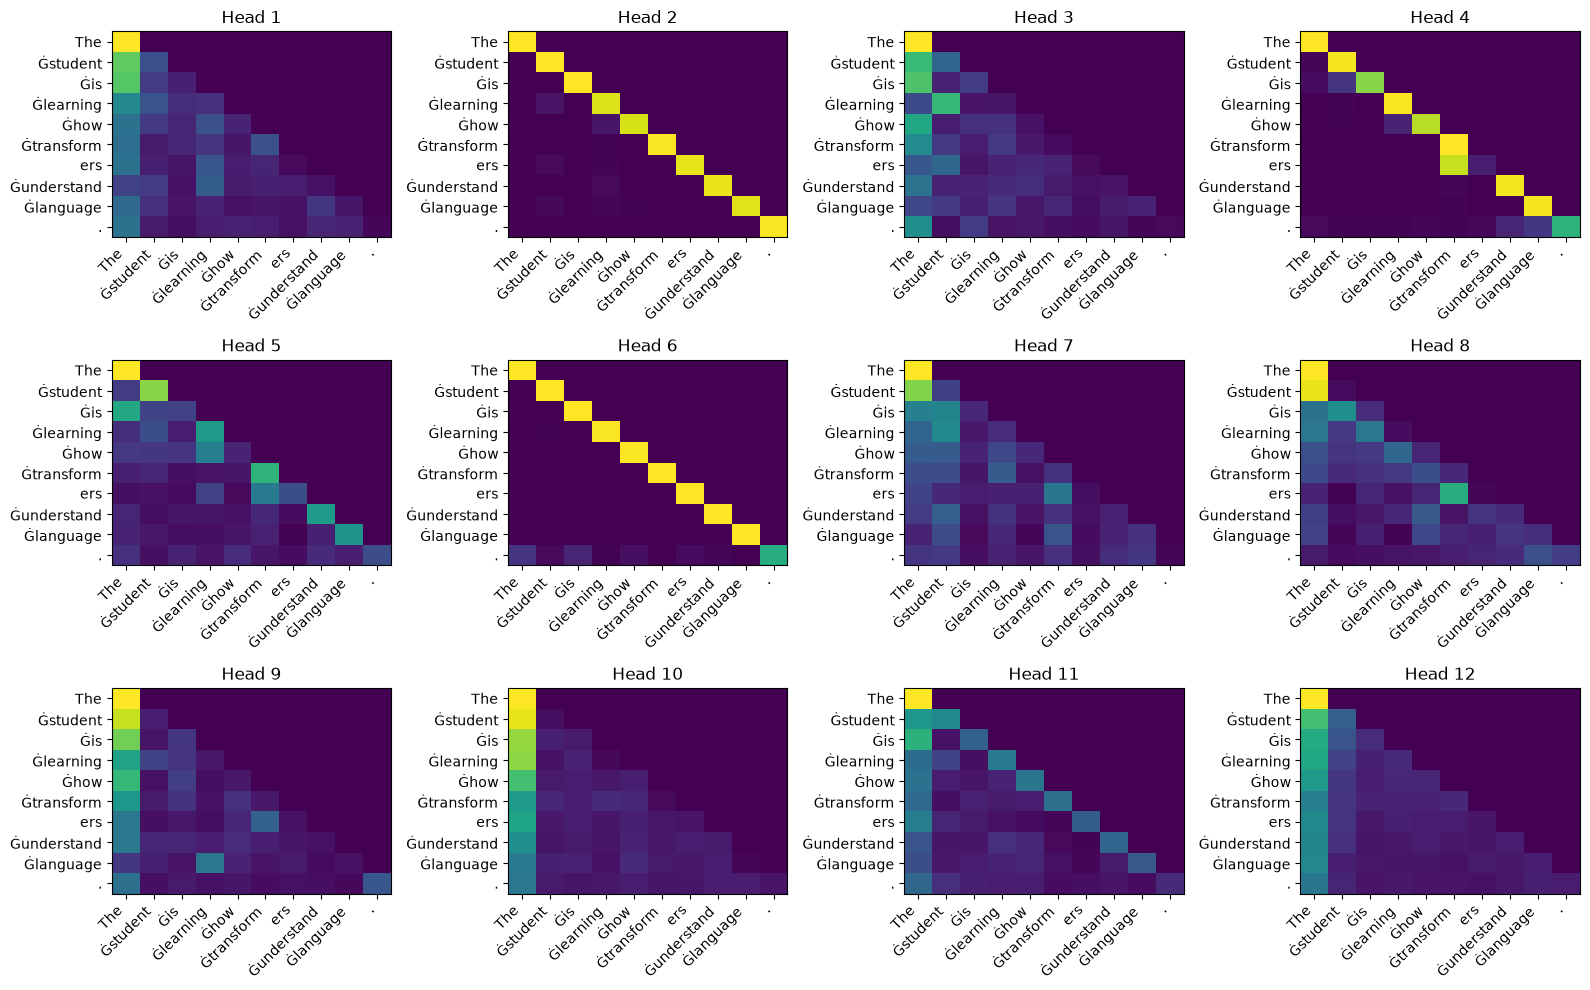

In [28]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for head in range(config.n_head):
    ax = axes[head // 4, head % 4]
    matrix = attentions[0][0, head].detach().cpu().numpy()
    ax.imshow(matrix, cmap="viridis", aspect="auto")
    ax.set_title(f"Head {head + 1}")
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=45, ha="right")
    ax.set_yticks(range(len(tokens)))
    ax.set_yticklabels(tokens)
plt.tight_layout()
plt.show()

In [37]:

# Get input IDs
input_ids = inputs["input_ids"]

# Create position IDs
position_ids = torch.arange(
    input_ids.shape[1],
    device=DEVICE
).unsqueeze(0)

with torch.no_grad():

    # Correct GPT2Model attribute paths
    token_embeddings = model.wte(input_ids)

    position_embeddings = model.wpe(position_ids)

    # Combine token and position embeddings
    block_input = token_embeddings + position_embeddings

    # First LayerNorm
    normalized_input = block.ln_1(block_input)

    # Self-attention
    attention_output = block.attn(
        normalized_input,
        use_cache=False,
        output_attentions=False
    )[0]

    # First residual connection
    attention_result = block_input + attention_output

    # Second LayerNorm
    normalized_attention = block.ln_2(attention_result)

    # Feed-forward network
    mlp_output = block.mlp(normalized_attention)

    # Second residual connection
    manual_output = attention_result + mlp_output

    # Official block output
    official_output = block(
        block_input,
        use_cache=False,
        output_attentions=False
    )[0]

    # Compare both outputs
    difference = torch.max(
        torch.abs(manual_output - official_output)
    ).item()

print("Token embeddings:", token_embeddings.shape)
print("Position embeddings:", position_embeddings.shape)
print("Block input:", block_input.shape)
print("Attention output:", attention_output.shape)
print("MLP output:", mlp_output.shape)
print("Manual vs official difference:", difference)


Token embeddings: torch.Size([1, 10, 768])
Position embeddings: torch.Size([1, 10, 768])
Block input: torch.Size([1, 10, 768])
Attention output: torch.Size([1, 10, 768])
MLP output: torch.Size([1, 10, 768])
Manual vs official difference: 0.0


In [40]:

# Select the Transformer block
block = model.h[0]

# Get input token IDs
input_ids = inputs["input_ids"]

with torch.no_grad():

    # Get hidden states entering the first Transformer block
    outputs = model(
        input_ids=input_ids,
        output_hidden_states=True,
        return_dict=True
    )

    hidden_states = outputs.hidden_states[0]

    # Apply first LayerNorm
    normalized_states = block.ln_1(hidden_states)

    # Combined QKV projection
    qkv = block.attn.c_attn(normalized_states)

    # Split into Query, Key and Value
    query, key, value = qkv.split(
        config.hidden_size,
        dim=2
    )

print("Query:", query.shape)
print("Key:", key.shape)
print("Value:", value.shape)


Query: torch.Size([1, 10, 768])
Key: torch.Size([1, 10, 768])
Value: torch.Size([1, 10, 768])


In [41]:
batch_size, sequence_length, hidden_size = query.shape
num_heads = config.n_head
head_dim = hidden_size // num_heads

def split_heads(tensor):
    return tensor.view(
        batch_size, sequence_length, num_heads, head_dim
    ).transpose(1, 2)

query_heads = split_heads(query)
key_heads = split_heads(key)
value_heads = split_heads(value)

print("Q heads:", tuple(query_heads.shape))
print("K heads:", tuple(key_heads.shape))
print("V heads:", tuple(value_heads.shape))

Q heads: (1, 12, 10, 64)
K heads: (1, 12, 10, 64)
V heads: (1, 12, 10, 64)


In [42]:
q = query_heads[:, 0, :, :]
k = key_heads[:, 0, :, :]
v = value_heads[:, 0, :, :]

scores = torch.matmul(q, k.transpose(-2, -1)) / (head_dim ** 0.5)
causal_mask = torch.triu(
    torch.ones(sequence_length, sequence_length, device=DEVICE, dtype=torch.bool),
    diagonal=1
)
scores = scores.masked_fill(causal_mask, torch.finfo(scores.dtype).min)
manual_attention_weights = torch.softmax(scores, dim=-1)
context = torch.matmul(manual_attention_weights, v)

print("Scores:", tuple(scores.shape))
print("Weights:", tuple(manual_attention_weights.shape))
print("Context:", tuple(context.shape))
print("Attention row sums:", manual_attention_weights.sum(dim=-1))

Scores: (1, 10, 10)
Weights: (1, 10, 10)
Context: (1, 10, 64)
Attention row sums: tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000]])


In [43]:
print("Attention module:")
print(block.attn)
print("\nMLP module:")
print(block.mlp)
print("\nLayerNorm 1:")
print(block.ln_1)
print("\nLayerNorm 2:")
print(block.ln_2)

Attention module:
GPT2Attention(
  (c_attn): Conv1D(nf=2304, nx=768)
  (c_proj): Conv1D(nf=768, nx=768)
  (attn_dropout): Dropout(p=0.1, inplace=False)
  (resid_dropout): Dropout(p=0.1, inplace=False)
)

MLP module:
GPT2MLP(
  (c_fc): Conv1D(nf=3072, nx=768)
  (c_proj): Conv1D(nf=768, nx=3072)
  (act): NewGELUActivation()
  (dropout): Dropout(p=0.1, inplace=False)
)

LayerNorm 1:
LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)

LayerNorm 2:
LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)


In [44]:
print("MLP expansion projection:")
print(block.mlp.c_fc)
print("\nMLP output projection:")
print(block.mlp.c_proj)

MLP expansion projection:
Conv1D(nf=3072, nx=768)

MLP output projection:
Conv1D(nf=768, nx=3072)


In [45]:
with torch.no_grad():
    residual_1 = block_input
    normalized_1 = block.ln_1(block_input)
    attention_output = block.attn(normalized_1, use_cache=False)[0]
    after_attention = residual_1 + attention_output

    residual_2 = after_attention
    normalized_2 = block.ln_2(after_attention)
    mlp_output = block.mlp(normalized_2)
    manual_block_output = residual_2 + mlp_output

    official_block_output = block(block_input, use_cache=False)[0]

max_difference = (official_block_output - manual_block_output).abs().max().item()
print("Input:", tuple(block_input.shape))
print("Attention output:", tuple(attention_output.shape))
print("After attention residual:", tuple(after_attention.shape))
print("MLP output:", tuple(mlp_output.shape))
print("Final block output:", tuple(manual_block_output.shape))
print("Manual vs official max difference:", max_difference)

Input: (1, 10, 768)
Attention output: (1, 10, 768)
After attention residual: (1, 10, 768)
MLP output: (1, 10, 768)
Final block output: (1, 10, 768)
Manual vs official max difference: 0.0


In [47]:

# Extract token embedding matrix
token_embedding_matrix = model.get_input_embeddings().weight

# Extract position embedding matrix
position_embedding_matrix = model.wpe.weight

print(
    "Token embedding table:",
    tuple(token_embedding_matrix.shape)
)

print(
    "Position embedding table:",
    tuple(position_embedding_matrix.shape)
)


Token embedding table: (50257, 768)
Position embedding table: (1024, 768)
